In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [21]:
# Cargar el archivo de Excel
df = pd.read_excel("C:/Users/julia/Downloads/_94f47dfe96414485b5def55bccbd7cb8_Datos_textosODS.xlsx")

# Mostrar las primeras 5 filas
df.head()

,textos,ODS
0,"""Aprendizaje"" y ""educación"" se consideran sinó...",4
1,No dejar clara la naturaleza de estos riesgos ...,6
2,"Como resultado, un mayor y mejorado acceso al ...",13
3,Con el Congreso firmemente en control de la ju...,16
4,"Luego, dos secciones finales analizan las impl...",5


In [22]:
# Revisar las categorías de los ODS

print("Categorías de ODS presentes:")
print(sorted(df["ODS"].unique()))

print("\nNúmero de categorías diferentes:")
print(df["ODS"].nunique())

print("\nCantidad de textos por ODS:")
print(df["ODS"].value_counts().sort_index())

Categorías de ODS presentes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]

Número de categorías diferentes:
16

Cantidad de textos por ODS:
ODS
1      505
2      369
3      894
4     1025
5     1070
6      695
7      787
8      446
9      343
10     352
11     607
12     312
13     464
14     377
15     330
16    1080
Name: count, dtype: int64


In [23]:
# 1. Resumen de las categorías


print("Categorías presentes:")
print(sorted(df["ODS"].unique()))

print("\nCategorías faltantes entre 1 y 17:")
ods_esperados = set(range(1, 18))
ods_presentes = set(df["ODS"].dropna().unique())

print(sorted(ods_esperados - ods_presentes))



# 2. Resumen general

print("\nDimensiones del dataset:", df.shape)

print("\nValores faltantes:")
print(df.isnull().sum())

print("\nFilas duplicadas completas:")
print(df.duplicated().sum())



# 3. Textos vacíos o duplicados

print("\nTextos duplicados:")
print(df["textos"].duplicated().sum())

print("\nTextos vacíos:")
print(df["textos"].isna().sum())

print("\nTipos de datos:")
print(df.dtypes)

Categorías presentes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]

Categorías faltantes entre 1 y 17:
[17]

Dimensiones del dataset: (9656, 2)

Valores faltantes:
textos    0
ODS       0
dtype: int64

Filas duplicadas completas:
0

Textos duplicados:
0

Textos vacíos:
0

Tipos de datos:
textos    object
ODS        int64
dtype: object


In [24]:
# Separar las variables predictoras y la variable objetivo

X = df["textos"]
y = df["ODS"]

print("Número total de textos:", len(X))
print("Número de etiquetas:", len(y))

print("\nDistribución de las categorías:")
print(y.value_counts().sort_index())

Número total de textos: 9656
Número de etiquetas: 9656

Distribución de las categorías:
ODS
1      505
2      369
3      894
4     1025
5     1070
6      695
7      787
8      446
9      343
10     352
11     607
12     312
13     464
14     377
15     330
16    1080
Name: count, dtype: int64


In [25]:


# División estratificada de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Textos de entrenamiento:", len(X_train))
print("Textos de prueba:", len(X_test))

print("\nDistribución de ODS en entrenamiento:")
print(y_train.value_counts().sort_index())

print("\nDistribución de ODS en prueba:")
print(y_test.value_counts().sort_index())

Textos de entrenamiento: 7724
Textos de prueba: 1932

Distribución de ODS en entrenamiento:
ODS
1     404
2     295
3     715
4     820
5     856
6     556
7     629
8     357
9     274
10    282
11    485
12    250
13    371
14    302
15    264
16    864
Name: count, dtype: int64

Distribución de ODS en prueba:
ODS
1     101
2      74
3     179
4     205
5     214
6     139
7     158
8      89
9      69
10     70
11    122
12     62
13     93
14     75
15     66
16    216
Name: count, dtype: int64


In [26]:
# Para representar numéricamente los textos se utilizó TfidfVectorizer de scikit-learn. Esta técnica permite asignar
# mayor peso a los términos que son relevantes para determinados documentos y que no aparecen con demasiada
# frecuencia en el conjunto de datos.
# Se configuró la conversión a minúsculas y la eliminación de acentos para reducir variaciones ortográficas. 
# Además, se utilizaron unigramas y bigramas (ngram_range=(1, 2)) con el propósito de capturar tanto palabras
# individuales como expresiones de dos palabras que podrían aportar información relevante para distinguir los ODS.
# Se establecieron valores de min_df=2 y max_df=0.95 para reducir la influencia de términos extremadamente infrecuentes 
# o demasiado frecuentes. La opción sublinear_tf=True permite utilizar una escala logarítmica en la frecuencia de los términos.
# El conjunto de datos se dividió en entrenamiento y prueba mediante una partición estratificada. El vectorizador se ajustó
# únicamente con los textos de entrenamiento, mientras que los textos de prueba se transformaron utilizando el vocabulario
# aprendido. De esta forma, se evita la fuga de información entre ambos conjuntos.

# Palabras vacías en español
stopwords_es = [
    "a", "al", "algo", "algunas", "algunos", "ante", "antes", "como",
    "con", "contra", "cual", "cuando", "de", "del", "desde", "donde",
    "el", "ella", "ellas", "ello", "ellos", "en", "entre", "era",
    "eran", "eres", "es", "esa", "esas", "ese", "eso", "esos",
    "esta", "estas", "este", "esto", "estos", "fue", "ha", "han",
    "hasta", "hay", "la", "las", "le", "les", "lo", "los", "más",
    "me", "mi", "mis", "muy", "no", "nos", "nosotros", "o", "para",
    "pero", "por", "que", "qué", "se", "sea", "ser", "si", "sin",
    "sobre", "son", "su", "sus", "también", "te", "tiene", "tienen",
    "toda", "todas", "todo", "todos", "tu", "tus", "un", "una","mas", "tambien",
    "uno", "unos", "unas", "y", "ya"
]

# Pipeline de preparación de textos
pipeline_tfidf = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            stop_words=stopwords_es,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    )
])

# Ajustar únicamente con los datos de entrenamiento
X_train_tfidf = pipeline_tfidf.fit_transform(X_train)

# Transformar los datos de prueba con el mismo vectorizador
X_test_tfidf = pipeline_tfidf.transform(X_test)

print("Dimensiones de la matriz TF-IDF de entrenamiento:",
      X_train_tfidf.shape)

print("Dimensiones de la matriz TF-IDF de prueba:",
      X_test_tfidf.shape)

#Ajuste del preprocesamiento

# Durante la inspección inicial de los componentes LSA, se observó que algunos estaban dominados por palabras funcionales
# del español, como “en”, “los”, “el”, “las” y “que”. Estos términos aportaban poca información temática y dificultaban 
# la interpretación de los tópicos.
# Por esta razón, se modificó el pipeline de preparación de datos incorporando una lista de palabras vacías (stopwords)
# en español. Este cambio busca reducir el ruido lingüístico y favorecer que los componentes LSA representen temas relacionados 
# con los ODS de manera más interpretable.
# Después de esta modificación, se volvieron a ejecutar las transformaciones TF-IDF y los análisis posteriores utilizando 
# únicamente el conjunto de entrenamiento para ajustar el modelo.

Dimensiones de la matriz TF-IDF de entrenamiento: (7724, 58643)
Dimensiones de la matriz TF-IDF de prueba: (1932, 58643)


In [27]:
# La transformación TF-IDF generó una matriz de 7.724 × 58.643 para el conjunto de entrenamiento y otra de 1.932 × 58.643
# para el conjunto de prueba. Esto indica que se identificaron 58.643 términos entre unigramas y bigramas. La alta dimensionalidad
# de la representación justifica aplicar una técnica de reducción de dimensionalidad como TruncatedSVD, que permitirá construir 
# el modelo LSA y facilitar el entrenamiento del clasificador.

# Obtener el vectorizador del pipeline
vectorizador = pipeline_tfidf.named_steps["tfidf"]

# Obtener los términos del vocabulario
vocabulario = vectorizador.get_feature_names_out()

print("Número de términos del vocabulario:", len(vocabulario))

print("Valores diferentes de cero en entrenamiento:",
      X_train_tfidf.nnz)

print("Total de valores posibles en entrenamiento:",
      X_train_tfidf.shape[0] * X_train_tfidf.shape[1])

# Porcentaje de valores diferentes de cero
porcentaje_no_ceros = (
    X_train_tfidf.nnz /
    (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
) * 100

print(f"Porcentaje de valores diferentes de cero: {porcentaje_no_ceros:.4f}%")

Número de términos del vocabulario: 58643
Valores diferentes de cero en entrenamiento: 534834
Total de valores posibles en entrenamiento: 452958532
Porcentaje de valores diferentes de cero: 0.1181%


Componentes: 10 | Varianza explicada acumulada: 0.0182 (1.82%)
Componentes: 11 | Varianza explicada acumulada: 0.0194 (1.94%)
Componentes: 12 | Varianza explicada acumulada: 0.0207 (2.07%)
Componentes: 13 | Varianza explicada acumulada: 0.0218 (2.18%)
Componentes: 14 | Varianza explicada acumulada: 0.0229 (2.29%)
Componentes: 15 | Varianza explicada acumulada: 0.0240 (2.40%)
Componentes: 16 | Varianza explicada acumulada: 0.0251 (2.51%)
Componentes: 17 | Varianza explicada acumulada: 0.0260 (2.60%)
Componentes: 18 | Varianza explicada acumulada: 0.0271 (2.71%)
Componentes: 19 | Varianza explicada acumulada: 0.0280 (2.80%)
Componentes: 20 | Varianza explicada acumulada: 0.0289 (2.89%)


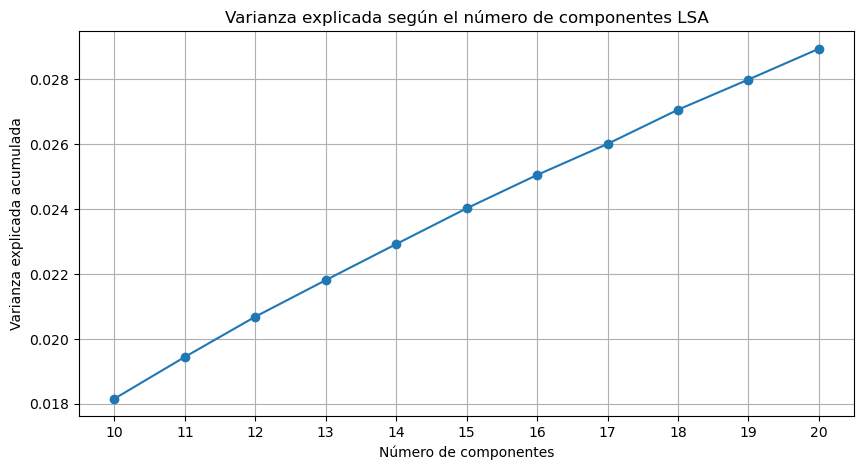

In [28]:
# La matriz TF-IDF contiene 81.039 términos y presenta una alta dispersión, ya que únicamente el 0,1181 % 
# de sus valores son diferentes de cero. Esto significa que la mayoría de los términos del vocabulario no 
# aparecen en cada documento. Debido a esta alta dimensionalidad y dispersión, se justifica aplicar TruncatedSVD 
# para reducir el número de variables y obtener una representación más compacta de los textos.


# Evaluar diferentes cantidades de componentes
n_componentes = range(10, 21)
varianza_explicada = []

for n in n_componentes:
    svd = TruncatedSVD(
        n_components=n,
        random_state=42
    )

    svd.fit(X_train_tfidf)

    varianza_explicada.append(
        svd.explained_variance_ratio_.sum()
    )

# Mostrar los resultados
for n, varianza in zip(n_componentes, varianza_explicada):
    print(
        f"Componentes: {n} | "
        f"Varianza explicada acumulada: {varianza:.4f} "
        f"({varianza * 100:.2f}%)"
    )

# Graficar la varianza explicada
plt.figure(figsize=(10, 5))
plt.plot(
    n_componentes,
    varianza_explicada,
    marker="o"
)

plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada según el número de componentes LSA")
plt.xticks(list(n_componentes))
plt.grid(True)
plt.show()

In [29]:
# Se amplió la exploración hasta 100 componentes para identificar un posible punto de inflexión en la varianza explicada acumulada.
# La curva presenta un crecimiento más pronunciado durante los primeros componentes y posteriormente un comportamiento más gradual, 
# pero no se observa un codo claramente definido. Por esta razón, se seleccionan inicialmente 20 componentes para el análisis LSA, 
# dado que este valor corresponde al límite superior del intervalo solicitado en la actividad. Para el modelo de clasificación,
# la cantidad de componentes podrá evaluarse posteriormente mediante validación cruzada y métricas de desempeño.



# Modelo LSA con 20 componentes
svd_lsa = TruncatedSVD(
    n_components=20,
    random_state=42
)

# Ajustar únicamente con los datos de entrenamiento
X_train_lsa = svd_lsa.fit_transform(X_train_tfidf)

# Transformar los datos de prueba
X_test_lsa = svd_lsa.transform(X_test_tfidf)

print("Dimensiones originales:", X_train_tfidf.shape)
print("Dimensiones después de LSA:", X_train_lsa.shape)

print(
    f"Varianza explicada acumulada: "
    f"{svd_lsa.explained_variance_ratio_.sum():.4f} "
    f"({svd_lsa.explained_variance_ratio_.sum() * 100:.2f}%)"
)

# Obtener los términos del vocabulario TF-IDF
terminos = pipeline_tfidf.named_steps["tfidf"].get_feature_names_out()

# Seleccionar los primeros 5 componentes
n_topicos = 5
n_palabras = 15

resultados_topicos = {}

for i in range(n_topicos):
    # Pesos de los términos en el componente
    pesos = svd_lsa.components_[i]

    # Índices de los términos con mayor peso
    indices_mayores = pesos.argsort()[-n_palabras:][::-1]

    # Obtener palabras y pesos
    palabras = terminos[indices_mayores]
    valores = pesos[indices_mayores]

    resultados_topicos[f"Componente {i + 1}"] = palabras

    print(f"\n{'=' * 60}")
    print(f"COMPONENTE {i + 1}")
    print(f"{'=' * 60}")

    for palabra, peso in zip(palabras, valores):
        print(f"{palabra:<35} {peso:.4f}")

Dimensiones originales: (7724, 58643)
Dimensiones después de LSA: (7724, 20)
Varianza explicada acumulada: 0.0289 (2.89%)

COMPONENTE 1
paises                              0.1361
desarrollo                          0.1153
mujeres                             0.1124
pueden                              0.0976
puede                               0.0917
politicas                           0.0914
agua                                0.0874
educacion                           0.0826
mayor                               0.0822
embargo                             0.0819
ejemplo                             0.0816
nivel                               0.0815
ocde                                0.0808
servicios                           0.0803
salud                               0.0793

COMPONENTE 2
derechos                            0.3204
derecho                             0.2965
derechos humanos                    0.2662
humanos                             0.2619
internacional                    

In [30]:
# Interpretación cualitativa de los componentes LSA
# Se analizaron las palabras con mayor peso en los cinco primeros componentes obtenidos mediante LSA. 
# A diferencia de los resultados iniciales, después de incorporar palabras vacías en español al preprocesamiento,
# los componentes presentan términos con mayor contenido semántico.
# El componente 2 se relaciona principalmente con los derechos humanos, la justicia, las leyes y las instituciones 
# jurídicas, por lo que se puede asociar cualitativamente con el ODS 16. El componente 3 presenta términos relacionados 
# con el género, las mujeres, el empleo y la participación laboral, por lo que se vincula principalmente con el ODS 5.
# El componente 4 contiene palabras asociadas con la educación, los estudiantes, las escuelas y el aprendizaje, lo que
# permite relacionarlo con el ODS 4. El componente 5 también presenta una fuerte asociación con la igualdad de género,
# la participación y la violencia contra las mujeres, por lo que se relaciona principalmente con el ODS 5.
# El componente 1 presenta un carácter más general, con términos relacionados con el desarrollo, las políticas públicas,
# el agua, la educación y las mujeres. Por tanto, no es posible asociarlo de manera concluyente con un único ODS. En general, 
# los resultados muestran que los componentes LSA pueden contener información relacionada con varios objetivos simultáneamente,
# ya que representan patrones latentes de coocurrencia de términos y no categorías ODS directamente.


# Definir el clasificador
clasificador = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Hiperparámetros que vamos a evaluar
parametros = {
    "C": [0.1, 1, 10],
    "class_weight": [None, "balanced"]
}

# Búsqueda de hiperparámetros mediante validación cruzada
grid_search = GridSearchCV(
    estimator=clasificador,
    param_grid=parametros,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Entrenar utilizando los datos LSA de entrenamiento
grid_search.fit(X_train_lsa, y_train)

# Mostrar los mejores parámetros
print("Mejores hiperparámetros:")
print(grid_search.best_params_)

print("\nMejor F1 macro en validación cruzada:")
print(grid_search.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Mejores hiperparámetros:
{'C': 10, 'class_weight': None}

Mejor F1 macro en validación cruzada:
0.7432467044911908


In [31]:
# Se realizó una búsqueda de hiperparámetros mediante GridSearchCV, evaluando tres valores de C y dos 
# configuraciones de class_weight, con una validación cruzada de tres particiones. Se utilizó el F1 macro 
# como métrica de selección, debido a que asigna el mismo peso a cada categoría ODS. La mejor configuración 
# fue C=10 y class_weight=None, con un F1 macro de 0,7432 en validación cruzada.
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Predicciones sobre el conjunto de prueba
y_pred = grid_search.predict(X_test_lsa)

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall_macro = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1_macro_test = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision macro: {precision_macro:.4f}")
print(f"Recall macro: {recall_macro:.4f}")
print(f"F1 macro: {f1_macro_test:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8100
Precision macro: 0.7636
Recall macro: 0.7476
F1 macro: 0.7540

Reporte de clasificación:
              precision    recall  f1-score   support

           1       0.81      0.78      0.80       101
           2       0.63      0.68      0.65        74
           3       0.84      0.89      0.86       179
           4       0.90      0.97      0.94       205
           5       0.91      0.92      0.92       214
           6       0.90      0.90      0.90       139
           7       0.85      0.89      0.87       158
           8       0.55      0.46      0.50        89
           9       0.58      0.49      0.53        69
          10       0.71      0.63      0.67        70
          11       0.73      0.75      0.74       122
          12       0.70      0.61      0.66        62
          13       0.81      0.75      0.78        93
          14       0.63      0.64      0.64        75
          15       0.76      0.64      0.69        66
          16       0.88      

In [32]:
# Evaluación del clasificador
# El modelo de Regresión Logística, entrenado sobre la representación LSA de 20 componentes, obtuvo una exactitud 
# (accuracy) de 0,81 en el conjunto de prueba. La precisión macro fue de 0,7636, el recall macro de 0,7476 y el F1 macro de 0,7540.
# El F1 macro se utilizó como métrica principal porque asigna la misma importancia a cada categoría ODS, 
# evitando que las clases con mayor cantidad de ejemplos dominen la evaluación. El modelo presentó un mejor desempeño 
# en los ODS 4, 5, 6 y 16, mientras que los ODS 8 y 9 obtuvieron los F1-scores más bajos. Esto sugiere que algunas 
# categorías pueden presentar similitudes temáticas que dificultan su diferenciación.

<Figure size 1200x1000 with 0 Axes>

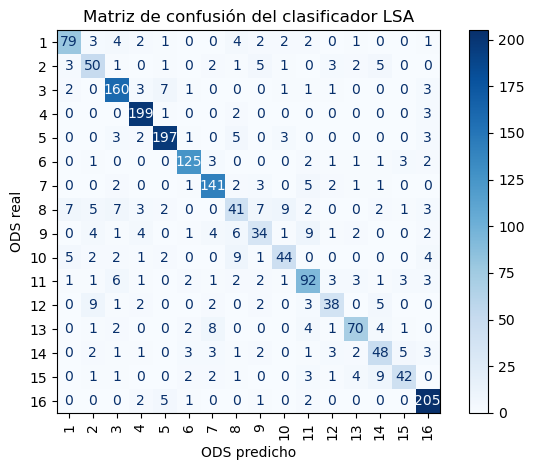

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Obtener las etiquetas ordenadas
etiquetas_ods = sorted(y_test.unique())

# Crear la matriz de confusión
plt.figure(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=etiquetas_ods,
    cmap="Blues",
    values_format="d",
    xticks_rotation="vertical"
)

plt.title("Matriz de confusión del clasificador LSA")
plt.xlabel("ODS predicho")
plt.ylabel("ODS real")
plt.tight_layout()
plt.show()

In [34]:
# Análisis de la matriz de confusión

# La matriz de confusión muestra que el modelo presenta un número importante de predicciones correctas 
# en categorías como los ODS 4, 5 y 16. Sin embargo, también se observan dificultades para distinguir 
# algunas categorías. Los ODS 8 y 9 presentan confusiones con categorías relacionadas con aspectos económicos, 
# sociales y laborales. Asimismo, se observan errores entre los ODS 12, 14 y 15, posiblemente debido a la
# similitud temática de algunos textos relacionados con el medioambiente y la sostenibilidad.

# Estos resultados muestran que, aunque el modelo alcanza una exactitud global del 80,90 %, su desempeño 
# no es uniforme entre todas las categorías. Por esta razón, resulta importante analizar las métricas individuales 
# de cada ODS y utilizar el F1 macro como medida complementaria.

In [35]:


# Crear una tabla con textos reales, etiquetas reales y predicciones
resultados_test = pd.DataFrame({
    "Texto": X_test.reset_index(drop=True),
    "ODS real": y_test.reset_index(drop=True),
    "ODS predicho": y_pred
})

# Mostrar cuatro ejemplos seleccionados aleatoriamente
muestra_test = resultados_test.sample(
    n=10,
    random_state=42
)

display(muestra_test)

,Texto,ODS real,ODS predicho
1078,Este modo sigue siendo defendido por los princ...,6,6
1655,El gasto per cápita se proyecta de acuerdo con...,3,3
1867,"Primero, revisa diferentes configuraciones de ...",11,11
942,Este artículo estudia el origen del control de...,16,16
331,Mientras que los países de renta media-alta es...,9,10
471,"Es evidente que, para lograr una igualdad real...",10,5
1345,"En una encuesta realizada en 2007, en todos lo...",5,5
305,"Por lo general, no plantean un problema para l...",6,6
966,A medida que el uso de vehículos eléctricos ha...,9,9
482,La aparición de plataformas y servicios de com...,9,9


In [36]:
# Evidencia de predicciones sobre datos de prueba

# Para comprobar el funcionamiento del modelo sobre datos no utilizados durante el aprendizaje, 
# se analizaron varias predicciones del conjunto de prueba. En la muestra seleccionada se observaron tanto
# clasificaciones correctas como errores entre distintas categorías ODS. Por ejemplo, algunos textos 
# pertenecientes al ODS 9 fueron clasificados como ODS 10 u ODS 11, mientras que un texto del ODS 10 fue clasificado como ODS 5.

# Estos resultados permiten observar directamente el comportamiento del modelo y evidencian que, aunque el clasificador 
# presenta un buen desempeño general, todavía existen confusiones entre determinadas categorías.
# Mostrar cuatro textos completos del conjunto de prueba
for indice, fila in muestra_test.head(4).iterrows():
    print("=" * 80)
    print(f"Texto {indice + 1}:")
    print(fila["Texto"])
    print(f"\nODS real: {fila['ODS real']}")
    print(f"ODS predicho: {fila['ODS predicho']}")
    print(
        "Resultado:",
        "Correcto" if fila["ODS real"] == fila["ODS predicho"]
        else "Incorrecto"
    )

Texto 1079:
Este modo sigue siendo defendido por los principales donantes, pero se está volviendo mucho más modulado y abierto a las partes interesadas recientemente reconocidas preocupadas por los impactos ecológicos, el desplazamiento de la población local, a menudo minorías en los respectivos países, y otros resultados sociales, culturales y económicos localizados indeseables. que, al cambiar quién se beneficia y quién pierde, cuestionan el uso del análisis social de costo-beneficio para defender proyectos a gran escala. La región de MRC, en particular, ha podido abrirse a muchas más voces en la investigación y en foros internacionales que discuten políticas y resultados de proyectos. Esto ha dado lugar a propuestas para la "gestión integrada de los recursos hídricos" (IWRM), que ahora cuenta con el apoyo de muchas instituciones donantes/prestamistas internacionales, incluido el Banco Asiático de Desarrollo (GWP 2003, Abdul-layev et al.

ODS real: 6
ODS predicho: 6
Resultado: Correc

In [39]:
# Evidencia de clasificación sobre datos no utilizados en el entrenamiento

# Se seleccionaron cuatro textos del conjunto de prueba para analizar las predicciones del modelo. 
# Los cuatro ejemplos fueron clasificados correctamente: ODS 6, ODS 3, ODS 11 y ODS 16. Esto proporciona 
# evidencia cualitativa del funcionamiento del clasificador sobre textos que no participaron en el proceso 
# de aprendizaje. Sin embargo, esta muestra no representa el desempeño global del modelo, que se evaluó 
# mediante las métricas calculadas sobre los 1.932 textos del conjunto de prueba.

# Pipeline completo de clasificación
pipeline_clasificacion = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            stop_words=stopwords_es,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "svd",
        TruncatedSVD(
            random_state=42
        )
    ),
    (
        "clasificador",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

# Hiperparámetros que se evaluarán
parametros_pipeline = {
    "svd__n_components": [50, 100],
    "clasificador__C": [0.1, 1, 10, 100],
    "clasificador__class_weight": [None, "balanced"]
}

# Búsqueda de hiperparámetros
grid_pipeline = GridSearchCV(
    estimator=pipeline_clasificacion,
    param_grid=parametros_pipeline,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Entrenamiento usando únicamente los textos de entrenamiento
grid_pipeline.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(grid_pipeline.best_params_)

print("\nMejor F1 macro en validación cruzada:")
print(f"{grid_pipeline.best_score_:.4f}")
# Primero se construyó un modelo de referencia utilizando una representación LSA fija de 20 componentes
# y se optimizaron los hiperparámetros de la Regresión Logística. Posteriormente, se construyó un pipeline
# integrado que incluye TF-IDF, reducción de dimensionalidad mediante TruncatedSVD y clasificación. En este 
# segundo experimento también se incluyó el número de componentes LSA como hiperparámetro, con el fin de
# evaluar conjuntamente las etapas de representación, reducción y clasificación.

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Mejores hiperparámetros:
{'clasificador__C': 10, 'clasificador__class_weight': None, 'svd__n_components': 100}

Mejor F1 macro en validación cruzada:
0.8248


In [40]:

# Predicciones sobre el conjunto de prueba
y_pred_pipeline = grid_pipeline.predict(X_test)

# Métricas generales
accuracy_pipeline = accuracy_score(y_test, y_pred_pipeline)

precision_pipeline = precision_score(
    y_test, y_pred_pipeline,
    average="macro",
    zero_division=0
)

recall_pipeline = recall_score(
    y_test, y_pred_pipeline,
    average="macro",
    zero_division=0
)

f1_pipeline = f1_score(
    y_test, y_pred_pipeline,
    average="macro",
    zero_division=0
)

print(f"Accuracy: {accuracy_pipeline:.4f}")
print(f"Precision macro: {precision_pipeline:.4f}")
print(f"Recall macro: {recall_pipeline:.4f}")
print(f"F1 macro: {f1_pipeline:.4f}")

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_pipeline,
        zero_division=0
    )
)

Accuracy: 0.8623
Precision macro: 0.8361
Recall macro: 0.8236
F1 macro: 0.8288

Reporte de clasificación:
              precision    recall  f1-score   support

           1       0.83      0.78      0.81       101
           2       0.73      0.82      0.77        74
           3       0.87      0.93      0.90       179
           4       0.93      0.98      0.95       205
           5       0.92      0.93      0.92       214
           6       0.93      0.93      0.93       139
           7       0.87      0.92      0.90       158
           8       0.62      0.54      0.58        89
           9       0.69      0.67      0.68        69
          10       0.71      0.66      0.68        70
          11       0.80      0.80      0.80       122
          12       0.89      0.79      0.84        62
          13       0.83      0.84      0.83        93
          14       0.91      0.81      0.86        75
          15       0.90      0.83      0.87        66
          16       0.94      

<Figure size 1200x1000 with 0 Axes>

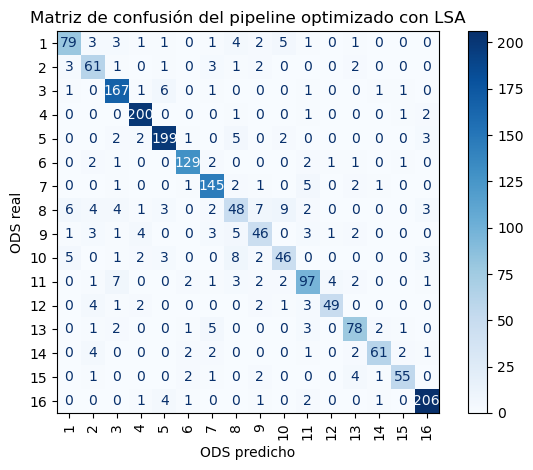

In [42]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

etiquetas_ods = sorted(y_test.unique())

plt.figure(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_pipeline,
    labels=etiquetas_ods,
    cmap="Blues",
    values_format="d",
    xticks_rotation="vertical"
)

plt.title("Matriz de confusión del pipeline optimizado con LSA")
plt.xlabel("ODS predicho")
plt.ylabel("ODS real")
plt.tight_layout()
plt.show()

In [ ]:
# Se amplió la búsqueda de hiperparámetros incluyendo valores de C entre 0.1 y 100. La mejor
# configuración continuó siendo C=10, con 100 componentes LSA y class_weight=None. El modelo obtuvo un 
# F1 macro de 0,8248 en validación cruzada y un F1 macro de 0,8288 en el conjunto de prueba, junto con
# un accuracy de 0,8623. La inclusión de valores superiores de C no produjo mejoras en el desempeño, por 
# lo que se seleccionó C=10 como valor final dentro del rango evaluado.